In [1]:
import sys
sys.path.append('/Users/leonardo.tessarolo/git/bayesian_bss/')

import numpy as np
import pandas as pd
import scipy.stats as st

from matplotlib import pyplot as plt

import arviz as az

from scipy import stats
from scipy.special import logsumexp
from matplotlib.colors import to_hex

from src import StudentTSource
np.random.seed(100)

# Ensaio de sensibilidade local — Separação Cega de Fontes Bayesiana

**Notação geral**

| Símbolo | Significado |
|---|---|
| $\mathbf{s}(n),\ \mathbf{x}(n)$, $n=1,\dots,N$ | fontes e misturas; realização $\mathcal X = \{\mathbf{x}(n)\}$ |
| $\underline{\mathbf{A}},\ \underline{\mathbf{B}}$ | matrizes verdadeiras de mistura e de separação |
| $\mathbf b = \mathrm{vec}(\mathbf B) \in \mathbb R^{d}$, $d = L^2$ | vetorização (*flattening*) de $\mathbf B$; idem $\underline{\mathbf b} = \mathrm{vec}(\underline{\mathbf B})$, $\mathbf i = \mathrm{vec}(\mathbf I_2)$ |
| $p_{s_\ell}(\cdot\,;\xi_s)$ | modelo da $\ell$-ésima fonte, $\ell = 1,\dots,L$ |
| $r_s$ | distribuição verdadeira das fontes |
| $p_{\mathbf b}(\mathbf b;\xi_p)$, $p_{\mathbf B\mid\mathcal X}(\mathbf B\mid\mathcal X)$ | distribuições a priori (sobre $\mathbf b$) e a posteriori |
| $\xi_p = (\boldsymbol\theta_p,\ \sigma_p,\ \nu_p)$ | parâmetros da priori: moda vetorial ($\boldsymbol\theta_p\in\mathbb R^d$), escala e graus de liberdade |
| $\xi_s = (\mu_s,\ \sigma_s,\ \nu_s)$ | parâmetros do modelo das fontes (verossimilhança): localização, escala e graus de liberdade |
| $\xi_p^{0},\ \xi_s^{0}$ | pontos base; os valores perturbados são indicados por $\xi_p^{*}$ e $\xi_s^{*}$ |
| $\xi_p^{a}=(\boldsymbol\theta_p^{a},\sigma_p^{a},\nu_p^{a})$, $\xi_s^{a}=(\mu_s^{a},\sigma_s^{a},\nu_s^{a})$, $a\in\{0,*\}$ | parâmetros base ($0$) e perturbados ($*$); sem sobrescrito, a notação é genérica |
| $\mathbf B_k$, $\mathbf b_k = \mathrm{vec}(\mathbf B_k)$, $k = 1,\dots,K$ | amostras MCMC da posteriori base |

### Contexto e modelo
 
**Problema:** estimar $\mathbf B$ a partir de $\mathbf x(n) = \mathbf A\mathbf s(n)$, com sistema misturador linear, instantâneo e igualmente determinado ($L = M$).
 
| Item | Valor |
|---|---|
| Fontes / observações | $L = 2$, $N = 1000$ |
| Mistura | $\mathbf A = \frac{\sqrt2}{2}\begin{bmatrix}1 & -1\\ 1 & 1\end{bmatrix}$ (rotação de 45°) |
| Separação ideal | $\underline{\mathbf B} = \mathbf A^{-1} = \frac{\sqrt2}{2}\begin{bmatrix}1 & 1\\ -1 & 1\end{bmatrix}$ |
| Realizações | $R = 30$ (sementes 0–29, as mesmas para todas as fontes) |


**Log-posteriori normalizada:**

$$
\frac1N\log p_{\mathbf B\mid\mathcal X}(\mathbf B\mid\mathcal X;\xi_p,\xi_s) = \log|\det\mathbf B| + \frac1N\sum_{n=1}^{N}\sum_{\ell=1}^{L}\log p_{s_\ell}\!\big([\mathbf B\mathbf x(n)]_\ell;\xi_s\big) + \frac1N\log p_{\mathbf b}(\mathbf b;\xi_p) + \text{cte}, \;\; \mathbf b = \mathrm{vec}(\mathbf B)
$$



## Fontes consideradas

Para as distribuições das fontes, toma-se como forma funcional a distribuição Student‑t com parâmetros de localização e escala: $p_{s_\ell}(s;\xi_s) \sim \mathcal{t}(\mu_s,\ \sigma_s,\ \nu_s)$. Assim, tem-se que

$$
p_{s_\ell}(s;\xi_s) = \frac{\Gamma\!\left(\frac{\nu_s+1}{2}\right)}{\Gamma\!\left(\frac{\nu_s}{2}\right)\sqrt{\nu_s\pi}\,\sigma_s}\left[1 + \frac{1}{\nu_s}\left(\frac{s-\mu_s}{\sigma_s}\right)^{2}\right]^{-\frac{\nu_s+1}{2}}.
$$

,df,KL_divergence_normal
0,3.000000,0.136241
190,3.171017,0.119265
434,3.390639,0.102240
755,3.679568,0.085163
1190,4.071107,0.068150
1821,4.639064,0.051112
2853,5.567957,0.034069
5096,7.586859,0.017034


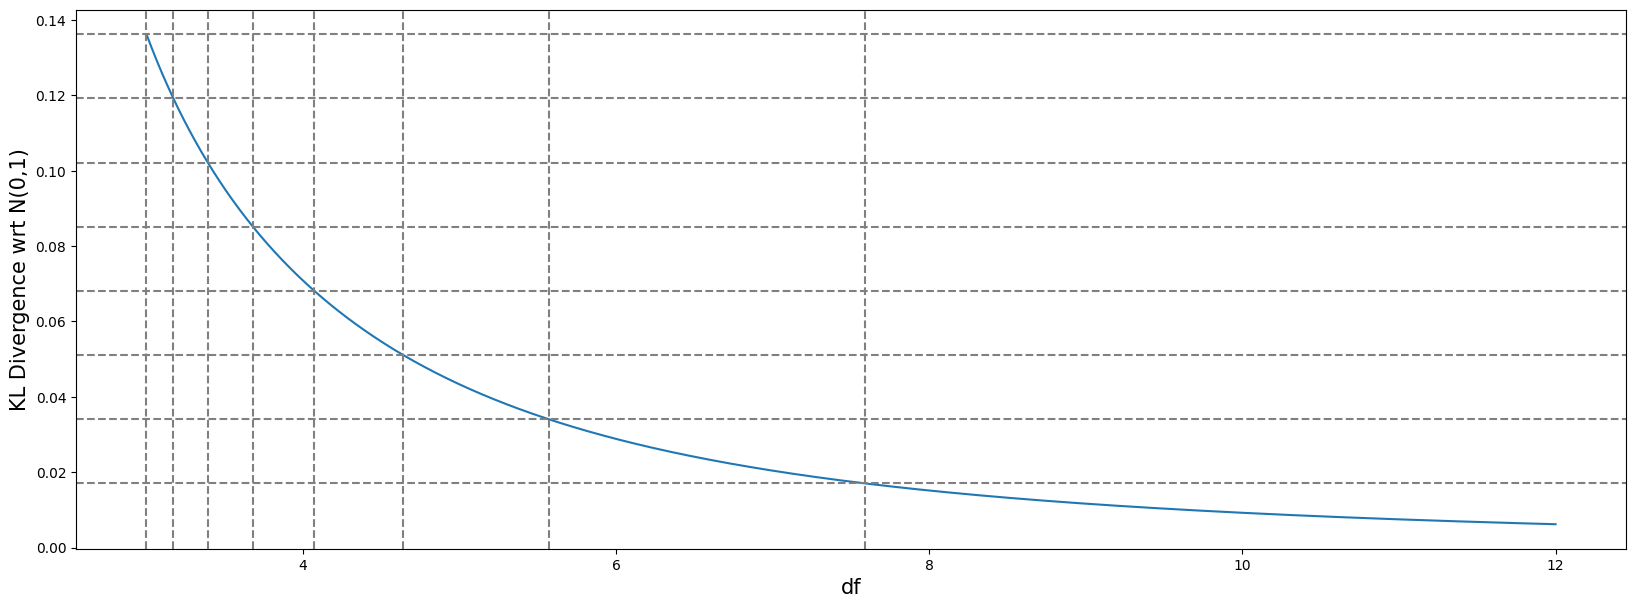

In [ ]:
# Number of distinct source distributions
N_SOURCE_DIST = 5

# Values of x to evaluate Student-t vs gaussian
probability_eval_x = np.linspace(
    -10,
    10,
    10000
)

# Evaluated degrees of freedom
eval_dfs = np.linspace(
    3,
    12,
    10000
)

# Function for calculating KL divergence
KL_fn = lambda df: stats.entropy(
    pk=StudentTSource(
        mu=0,
        sigma=np.sqrt((df-2)/df),
        df=df
    ).get()(
        probability_eval_x
    ),
    qk=stats.norm.pdf(probability_eval_x)
)

# Get divergences for specified dfs
results = []
for df in eval_dfs:
    results.append(
        {
            'df': df,
            'KL_divergence_normal': KL_fn(df=df)
        }
    )

# Get df for plotting
plot_df = pd.DataFrame(results)

# Calculate evenly spaced KL Divergence values
KL_range = plot_df.KL_divergence_normal.max()
KL_step = KL_range/(N_SOURCE_DIST)
KL_values = np.array([
    KL_step*i for i in range(1, N_SOURCE_DIST+1)
])

# Get df values that approximately yield chosen KL Values
get_KL_df = lambda KL: plot_df.df.values[
    np.argmin([KL_i - KL for KL_i in plot_df.KL_divergence_normal.values if KL_i >= KL])
]
df_KL_values = np.array([
    get_KL_df(KL=KL) for KL in KL_values
])

fig, ax = plt.subplots(
    nrows=1, ncols=1,
    figsize=(20,7)
)

ax.plot(
    plot_df.df,
    plot_df.KL_divergence_normal
)

[
    ax.axhline(
        KL,
        linestyle='--',
        color='gray'
    ) for KL in KL_values
]

[
    ax.axvline(
        df,
        linestyle='--',
        color='gray'
    ) for df in df_KL_values
]

ax.set_xlabel(
    'df',
    fontsize=15
)

ax.set_ylabel(
    'KL Divergence wrt N(0,1)',
    fontsize=15
)

plot_df[plot_df.df.isin(df_KL_values)]



### Seleção das distribuições verdadeiras das fontes

São consideradas **cinco distribuições verdadeiras** $r_s$,
identificadas por rs1–rs5, pertencentes à família Student-t:

$$
r_s(s;\nu_s)
=
t\left(
s;\,
\mu_s=0,\,
\sigma_s=\sqrt{\frac{\nu_s-2}{\nu_s}},\,
\nu_s
\right),
\qquad \nu_s>2.
$$

Todas as fontes possuem média zero e variância unitária. A seleção
dos graus de liberdade busca distribuir as fontes em níveis
igualmente espaçados de divergência em relação à normal padrão.

Para essa seleção, utiliza-se uma aproximação discretizada da
divergência KL, calculada sobre uma grade uniforme
$x_j\in[-10,10]$, com $J=10\,000$ pontos:

$$
\widetilde p_j(\nu_s)
=
\frac{r_s(x_j;\nu_s)}
{\sum_{k=1}^{J}r_s(x_k;\nu_s)},
\qquad
\widetilde q_j
=
\frac{\phi(x_j)}
{\sum_{k=1}^{J}\phi(x_k)},
$$

$$
\widehat D_{\mathrm{KL}}(\nu_s)
=
\sum_{j=1}^{J}
\widetilde p_j(\nu_s)
\log\frac{\widetilde p_j(\nu_s)}{\widetilde q_j},
$$

em que $\phi$ é a densidade da normal padrão.

Os cinco níveis-alvo são definidos por

$$
d_i
=
d_{\max}
-
\frac{i-1}{4}(d_{\max}-d_{\min}),
\qquad i=1,\ldots,5,
$$

com

$$
d_{\max}=\widehat D_{\mathrm{KL}}(3),
\qquad
d_{\min}=\widehat D_{\mathrm{KL}}(12).
$$

Os graus de liberdade são obtidos numericamente resolvendo
$\widehat D_{\mathrm{KL}}(\nu_{s,i})=d_i$.

| Fonte | $\nu_s$ | $\sigma_s^2$ | $\widehat D_{\mathrm{KL}}$ |
|---|---:|---:|---:|
| rs1 | 3,000000 | 0,333333 | 0,136241 |
| rs2 | 3,369100 | 0,406370 | 0,103727 |
| rs3 | 3,990506 | 0,498810 | 0,071214 |
| rs4 | 5,258728 | 0,619680 | 0,038700 |
| rs5 | 12,000000 | 0,833333 | 0,006187 |

Assim, rs1 é a fonte mais distante da normal padrão segundo o
critério adotado, enquanto rs5 é a mais próxima. O espaçamento é
uniforme nos níveis-alvo de KL, e não nos graus de liberdade.

**Limitação numérica:** a divergência utilizada na seleção é
calculada com densidades discretizadas e renormalizadas no
intervalo finito. Portanto, não corresponde exatamente à
divergência contínua sobre toda a reta real. A seleção depende
da grade e do intervalo escolhidos.

**HDIs de 95% e divergência KL em relação à normal padrão.**
Todas as distribuições possuem média zero e variância unitária.

| Distribuição | HDI de 95% | Variação do HDI vs. gaussiana | $\widehat{D}_{\mathrm{KL}}(r_s \,\|\, \mathcal{N}(0,1))$ |
|:---|:---:|---:|---:|
| rs1 ($\nu_s = 3{,}000000$) | $\pm 1{,}8374$ | −6,25% | 0,136241 |
| rs2 ($\nu_s = 3{,}369037$) | $\pm 1{,}9086$ | −2,62% | 0,103732 |
| rs3 ($\nu_s = 3{,}990099$) | $\pm 1{,}9627$ | +0,14% | 0,071230 |
| rs4 ($\nu_s = 5{,}258326$) | $\pm 1{,}9940$ | +1,74% | 0,038707 |
| rs5 ($\nu_s = 12{,}000000$) | $\pm 1{,}9890$ | +1,48% | 0,006187 |
| Gaussiana $\mathcal{N}(0,1)$ | $\pm 1{,}9600$ | 0,00% | 0 |

A variação do HDI corresponde à variação percentual de sua largura
em relação à largura do HDI da normal padrão. A divergência KL
é a aproximação discretizada utilizada na seleção das fontes,
calculada na grade espacial finita e expressa em nats.

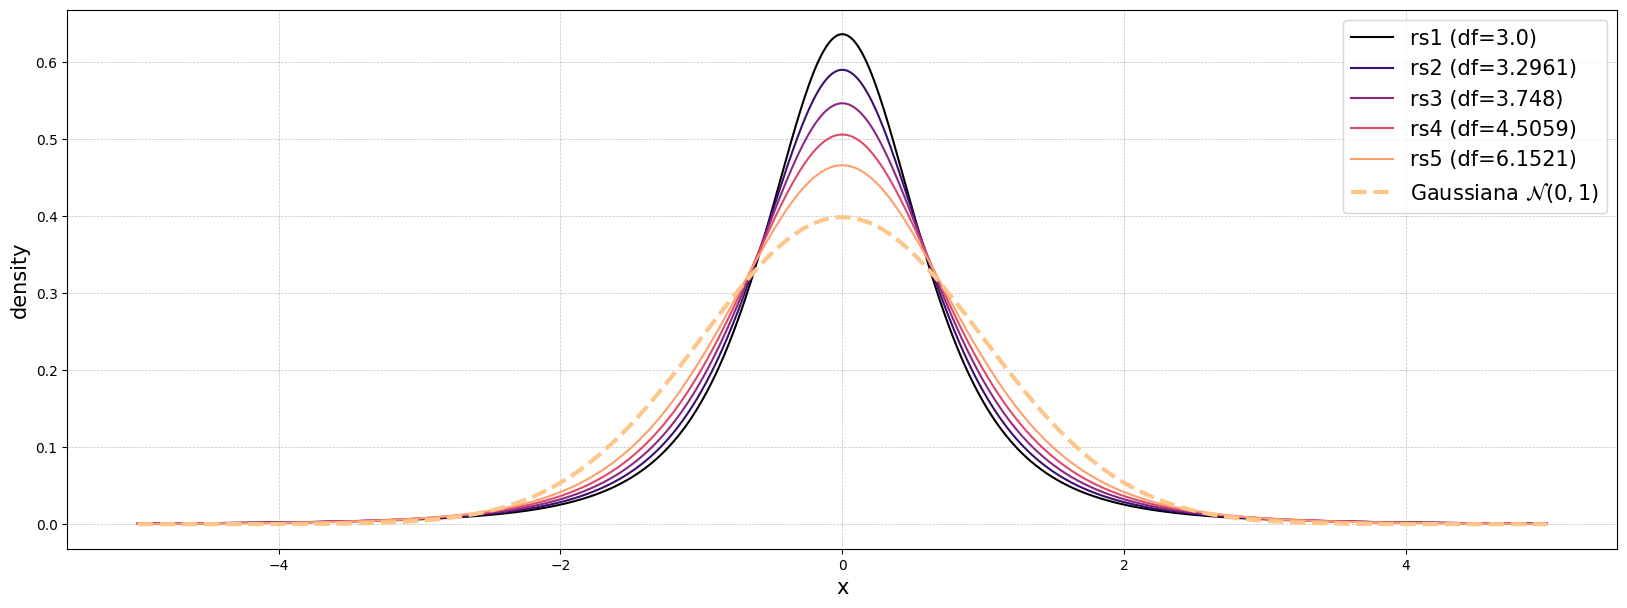

In [14]:
###############
# Plot fontes #
###############

# Graus de liberdade e valores x avaliados
evaluated_dfs = np.flip(df_KL_values)
evaluated_x = np.linspace(-5,5,1000)

# Colormap (mesmo padrão dos métodos de IS)
cmap = plt.get_cmap('magma')
colors = cmap(np.linspace(0.0, 0.8, len(evaluated_dfs)))

# Instantiate sources
sources = {str(df): StudentTSource(
    mu=0,
    sigma=np.sqrt((df-2)/df),
    df=df
) for df in evaluated_dfs}

fig, ax = plt.subplots(
    nrows=1, ncols=1,
    figsize=(20,7)
)

ax.set_xlabel('x', fontsize=15)
ax.set_ylabel('density', fontsize=15)

# Plot t
for color, (df, s), i in zip(colors, sources.items(), range(1, len(sources.items())+1)):
    ax.plot(
        evaluated_x,
        s.get()(evaluated_x),
        color=color,
        label='rs{} (df={})'.format(i, round(float(df),4))
    )

# Plot gaussiana N(0,1) com destaque
ax.plot(
    evaluated_x,
    st.norm.pdf(evaluated_x, loc=0, scale=1),
    color=cmap(0.88),
    linestyle='--',
    linewidth=3,
    label=r'Gaussiana $\mathcal{N}(0,1)$',
    zorder=10
)

ax.grid(
    visible=True,
    which='both',
    axis='both',
    **{
        'linestyle': '--',
        'color': 'gray',
        'linewidth': .5,
        'alpha': .5
    }
)

l = ax.legend(fontsize=15)


## Priori considerada

Para a distribuição a priori, adota-se como forma funcional a distribuição Student-t multivariada sobre $\mathbf b = \mathrm{vec}(\mathbf B) \in \mathbb R^{d}$, com $d = L^2$, localização $\boldsymbol\theta_p$ e **matriz de forma** $\sigma_p^2\mathbf I_d$. Para $\nu_p > 2$, a matriz de covariância é $\operatorname{Cov}(\mathbf b) = \frac{\nu_p}{\nu_p - 2}\,\sigma_p^2\,\mathbf I_d$. Assim, tem-se $p_{\mathbf b}(\mathbf b;\,\xi_p) \sim \mathcal T(\boldsymbol\theta_p, \sigma_p, \nu_p)$:
 
$$
p_{\mathbf b}(\mathbf b;\,\xi_p)
= \frac{\Gamma\!\left(\frac{\nu_p + d}{2}\right)}{\Gamma\!\left(\frac{\nu_p}{2}\right)(\nu_p\pi)^{d/2}\,\sigma_p^{d}}
\left[1 + \frac{(\mathbf b - \boldsymbol\theta_p)^\top(\mathbf b - \boldsymbol\theta_p)}{\nu_p\,\sigma_p^2}\right]^{-\frac{\nu_p + d}{2}}
$$
 
É a generalização, com cauda pesada, da priori gaussiana usada na Qualificação.

## Objetivos científicos e perguntas

**Objetivo:** quantificar o quanto $p_{\mathbf B\mid\mathcal X}$ é sensível a perturbações locais de $\xi_p$ e $\xi_s$.

**Perguntas:**

1. **Priori:** quanto os momentos a posteriori de $b_{ij}$ (média, variância, assimetria, curtose) mudam com variações locais em $\boldsymbol\theta_p$, $\sigma_p$ e $\nu_p$?
2. **Modelo das fontes:** quanto a média a posteriori de $b_{ij}$ (média, variância, assimetria, curtose) mudam com variações locais em $\mu_s$, $\sigma_s$ e $\nu_s$?
3. **Sensibilidade:** qual é a sensibilidade (derivada) da média a posteriori em relação a perturbações nos parâmetros da priori e do modelo das fontes?
4. **Efeito de $r_s$:** a sensibilidade muda ao passar de fontes de cauda pesada (rs1) para fontes quase gaussianas (rs10)?
5. **Priori × verossimilhança:** com $N = 1000$, qual dos dois componentes domina a posteriori?


## Importance sampling autonormalizado

A amostragem de importância permite estimar esperanças e momentos sob uma distribuição alvo a partir de amostras de outra distribuição, mais simples de amostrar ou já disponível. A mesma amostra pode ser reutilizada para diferentes funções $h$ e diferentes alvos, ajustando os **pesos de importância**.

**Ideia geral e derivação (Paulino et al., 2018, p. 290–291, eq. 7.18 e 7.19):** sejam $p^{0}(\boldsymbol{\theta})$ a densidade base e $p^{\ast}(\boldsymbol{\theta})$ a densidade alvo, definidas sobre o espaço paramétrico $\Phi_{\boldsymbol{\theta}}$, com $p^{0}>0$. Para uma função integrável $h$:

$$
\begin{aligned}
\mathcal{H}^{\ast}
&= \mathbb{E}_{p^{\ast}}[h(\boldsymbol{\theta})] \\
&= \int_{\Phi_{\boldsymbol{\theta}}} h(\boldsymbol{\theta})\,p^{\ast}(\boldsymbol{\theta})\,\mathrm{d}\boldsymbol{\theta} \\
&= \int_{\Phi_{\boldsymbol{\theta}}} h(\boldsymbol{\theta})\,\underbrace{\frac{p^{\ast}(\boldsymbol{\theta})}{p^{0}(\boldsymbol{\theta})}}_{w(\boldsymbol{\theta})}\,p^{0}(\boldsymbol{\theta})\,\mathrm{d}\boldsymbol{\theta} \\
&= \mathbb{E}_{p^{0}}[h(\boldsymbol{\theta})\,w(\boldsymbol{\theta})].
\end{aligned}
$$

Com $\boldsymbol{\theta}_k \sim p^{0}$ e $w_k = w(\boldsymbol{\theta}_k)$, a estimativa de Monte Carlo é:

$$
\widehat{\mathcal{H}}^{\ast}_{\mathrm{IS}} = \frac{1}{K}\sum_{k=1}^{K} h(\boldsymbol{\theta}_k)\,w_k.
$$

Na forma autonormalizada, os pesos são divididos pela sua soma:

$$
\widehat{\mathcal{H}}^{\ast}_{\mathrm{IS}}
= \frac{\sum_{k=1}^{K} h(\boldsymbol{\theta}_k)\,w_k}{\sum_{k=1}^{K} w_k}
= \sum_{k=1}^{K} \tilde{w}_k\, h(\boldsymbol{\theta}_k),
\qquad
\tilde{w}_k = \frac{w_k}{\sum_{k'=1}^{K} w_{k'}}.
$$

**Aplicação ao ensaio:** amostras $\mathbf{B}_k \sim p_{\mathbf{B}\mid\mathcal{X}}(\mathbf{B}\mid\mathcal{X};\xi_p^{0},\xi_s^{0})$, com $k=1,\dots,K$:

$$
\widehat{\mathbb{E}}_{\xi_p^{\ast},\xi_s^{\ast}}\big[h(\mathbf{B})\big]
= \sum_{k=1}^{K} \tilde{w}_k\, h(\mathbf{B}_k),
\qquad
\tilde{w}_k = \frac{w_k}{\sum_{k'=1}^{K} w_{k'}}.
$$

**Pesos brutos $w_k$:**

*Posteriori:*

$$
\log w_k
= \log p_{\mathbf{B}\mid\mathcal{X}}(\mathbf{B}_k\mid\mathcal{X};\xi_p^{\ast},\xi_s^{\ast})
- \log p_{\mathbf{B}\mid\mathcal{X}}(\mathbf{B}_k\mid\mathcal{X};\xi_p^{0},\xi_s^{0}).
$$

*Priori*, quando $\xi_s^{\ast}=\xi_s^{0}$ (pesos equivalentes após a autonormalização):

$$
\log w_k = \log p_{\mathbf{b}}(\mathbf{b}_k;\xi_p^{\ast}) - \log p_{\mathbf{b}}(\mathbf{b}_k;\xi_p^{0}).
$$

*Modelo das fontes*, quando $\xi_p^{\ast}=\xi_p^{0}$ (pesos equivalentes após a autonormalização):

$$
\log w_k
= \sum_{n=1}^{N}\sum_{\ell=1}^{L}
\Big[
\log p_{s_\ell}\big([\mathbf{B}_k\mathbf{x}(n)]_\ell;\xi_s^{\ast}\big)
- \log p_{s_\ell}\big([\mathbf{B}_k\mathbf{x}(n)]_\ell;\xi_s^{0}\big)
\Big].
$$

O termo $N\log|\det\mathbf{B}_k|$ se cancela.

A soma das diferenças de log-priori e log-verossimilhança fornece os pesos para alterações simultâneas de $\xi_p$ e $\xi_s$, usados na estimativa autonormalizada.

**Quantidades de interesse:** média, variância, assimetria e curtose de cada $b_{ij}$, ponderadas por $\tilde{w}_k$. A média ponderada é a estimativa $\widehat{\mathbf{B}}_{\mathrm{MMSE}}^{\ast}$ sob $(\xi_p^{\ast},\xi_s^{\ast})$.

## Parâmetros perturbados e intervalos

### Variação da priori ($\xi_s^{*} = \xi_s^{0}=r_{s}$, para cada uma das fontes rs1-rs10)

| Perturbação | Base | Alvos | Justificativa do intervalo |
|---|---|---|---|
| **Moda** $\boldsymbol\theta_p$ | $\boldsymbol\theta_p^0 = \tfrac12(\underline{\mathbf b} + \mathbf i)$, $\sigma_p^0 = \sqrt{1/3}$, $\nu_p^0 = 3$ | $\boldsymbol\theta_p^*(\alpha) = (1-\alpha)\,\underline{\mathbf b} + \alpha\,\mathbf i$, $\alpha \in [0, 1]$ (31 pts; inclui a base $\alpha = 0{,}5$) | Homotopia da moda da priori, indo da solução ideal à identidade; a base no meio do caminho busca manter as duas extremidades dentro da faixa de confiabilidade do PSIS. |
| **Escala** $\sigma_p$ | $\boldsymbol\theta_p^0 = \underline{\mathbf b}$, $\sigma_p^0 = 0{,}5$, $\nu_p^0 = 3$ | $\sigma_p^* \in [10^{-1}, 10^{1}]$ (31 pts, espaçamento logarítmico; a base $\sigma_p^0 = 0{,}5$ não pertence à grade) | Vai de priori informativa a pouco informativa, utilizando os mesmos extremos 0,1 e 10 do experimento da Qualificação; a confiabilidade da reponderação é avaliada pelo diagnóstico $\hat k$ do PSIS. |
| **Cauda** $\nu_p$ | $\boldsymbol\theta_p^0 = \underline{\mathbf b}$, $\sigma_p^0 = \sqrt{1/3}$, $\nu_p^0 = 3$ | $\nu_p^* \in \{3, \dots, 12\}$, com $\sigma_p^* = \sqrt{(\nu_p^* - 2)/\nu_p^*}$ | Variação do peso de cauda da priori, mantendo constante sua matriz de covariância, $\operatorname{Cov}(\mathbf b) = \mathbf I_{L^2}$. A faixa abrange distribuições progressivamente mais próximas da normal. A confiabilidade do PSIS é verificada em cada ponto. |


### Variação do modelo das fontes (priori fixa: $\boldsymbol\theta_p^0 = \underline{\mathbf b}$, $\sigma_p^0 = \sqrt{1/3}$, $\nu_p^0 = 3$)
 
| Perturbação | Base | Alvos | Justificativa do intervalo |
|---|---|---|---|
| **Localização** $\mu_s$ | $\mu_s^0 = 0$ | $\mu_s^*\in[-0.15;,0.15]$ (31 pts) | Faixa ao redor da localização do modelo das fontes base, selecionada com base nos diagnósticos anteriores do PSIS. |
| **Escala** $\sigma_s$ | $\sigma_s^0$ de $r_s$ | $p\in[0{.}97;,1{.}03]$, 31 pts linearmente espaçados (inclui $p=1$) | Faixa relativa única para rs1–rs10, ampliada em relação à execução anterior, na qual $\hat k \le 0{,}22$ em toda a faixa de $\pm 1{,}5\%$. |
| **Cauda** $\nu_s$ | $\nu_s^0$ de $r_s$, com $\sigma_s^0 = \sqrt{(\nu_s^0 - 2)/\nu_s^0}$ | $\nu_s^* = r\,\nu_s^0$, $r\in[0{,}95;,1{,}05]$ | Faixa **relativa** à base de cada fonte, preservando $\operatorname{Var}(S) = 1$. A varredura absoluta $\{3, \dots, 12\}$ foi abandonada: na execução anterior, o PSIS falhou ($\hat k > 0{,}7$) a poucos graus de liberdade da base, pois a perturbação na verossimilhança se acumula sobre $2N$ termos. A faixa $\pm 5\%$ foi escolhida pela fonte mais sensível (rs1), para a qual $\nu_s^* \ge 2{,}78 > 2$. |
 
**Controle da dispersão nas perturbações de cauda:** diferentemente das análises de escala, nas quais $\sigma_p$ ou $\sigma_s$ são os parâmetros perturbados, as análises de peso de cauda ajustam a escala em função dos graus de liberdade, segundo $\sigma(\nu) = \sqrt{(\nu - 2)/\nu}$. Dessa forma, preservam-se a matriz de covariância identidade da priori e a variância unitária das fontes.


## Metodologia — fluxo geral

Fluxo inspirado no *power-scaling* (Kallioinen et al.): **perturbar priori e verossimilhança separadamente e avaliar os impactos sobre a posteriori base**. A diferença é que, em vez de usar potências da priori ou da verossimilhança, perturbam-se individualmente os parâmetros em $(\xi_p, \xi_s)$.
 
1. **MCMC** na posteriori base $p_{\mathbf B\mid\mathcal X}(\mathbf B\mid\mathcal X;\,\xi_p^0, \xi_s^0)$, executado separadamente para cada fonte, varredura e realização.
2. **Varredura da vizinhança** dos parâmetros: pesos de IS $\rightarrow$ PSIS $\rightarrow$ $\hat k$ $\rightarrow$ momentos ponderados.
3. **Sensibilidade local:** $\operatorname{Cov}_0\big(h(\mathbf B),\, \eta_{\xi_a}(\mathbf B)\big)$ no ponto base, sem reponderação.
4. **Comparação:** inclinação local $\times$ curva de variação obtida por IS (por fonte e por realização).


### Amostragem base — Barker MH (NumPyro)

Substitui o Metropolis-Hastings de passeio aleatório da Qualificação: a proposta usa o gradiente da log-posteriori.
 
| Configuração | Valor |
|---|---|
| Cadeias / amostras | 4 cadeias; $K = 30.000$ amostras finais (as últimas 7.500 de cada cadeia) |
| Aquecimento | 5.000 iterações, com adaptação do passo e da matriz de massa (diagonal); aceitação-alvo de 0,5 |
| Convergência | $\hat R$ (Gelman–Rubin, NumPyro) $< 1{,}01$ em todos os $b_{ij}$, calculado sobre as 7.500 amostras finais de cada cadeia, a cada 500 iterações, em 2 avaliações consecutivas |
| Máx. iterações | 20.000 por cadeia, incluindo o aquecimento; o critério de convergência é testado a partir de 13.500 iterações ($7.500 + 5.000 + 500$) |
| Inicialização | $\underline{\mathbf B} + \boldsymbol\varepsilon$, $\varepsilon_{ij} \sim t_3(0;\, 0{,}05)$; os mesmos 4 pontos iniciais e a mesma semente do amostrador são usados em todas as realizações, fontes e varreduras |


## Equacionamento

### PSIS e diagnóstico $\hat k$ (Vehtari et al., 2024)

**Motivação:** quando a posteriori alvo e a base diferem muito em certas regiões, a distribuição dos pesos $w_k$ ganha uma cauda longa. Poucas amostras passam a dominar a estimativa, que fica instável. O PSIS controla essa cauda.

- Ajusta uma Pareto generalizada às $M_{\text{cauda}} = \lfloor\min(0{,}2K,\ 3\sqrt K)\rfloor$ maiores razões.
- Substitui essas razões pelas estatísticas de ordem esperadas: $w_{(K-M_{\text{cauda}}+m)} = F^{-1}\!\left(\frac{m-1/2}{M_{\text{cauda}}}\right)$, $m=1,\dots,M_{\text{cauda}}$. As estatísticas de ordem são os valores esperados, sobre os pesos ordenados, da distribuição Pareto ajustada.
- $\hat k$ = forma da Pareto ajustada, que indica quantos momentos dos pesos são finitos. **$\hat k < 0{,}7$ → confiável** (com $K = 30.000$, o limiar é $\min(1 - 1/\log_{10}K,\ 0{,}7) = 0{,}7$).
- Eficiência relativa do MCMC: $R_{\text{eff}} = \text{ESS}_{\min}/K$.


→ A curva $\hat k$ × parâmetro delimita **a faixa em que a varredura da vizinhança dos parâmetros perturbados vale**.


Quando os pesos de importância têm cauda pesada, poucos valores extremos podem dominar a estimativa, tornando-a muito variável entre realizações. O PSIS substitui os maiores pesos por quantis da Pareto ajustada, reduzindo a variabilidade amostral (ruído amostral) desses extremos e, consequentemente, da estimativa. O objetivo não é diminuir todos os pesos grandes, mas regularizar sua contribuição, com baixo viés, para obter estimativas mais estáveis.

----

**Justificativa da expressão das estatísticas de ordem.** 

Seja $F$ a CDF da Pareto ajustada à cauda. Se $Y$ segue essa distribuição, a transformação $U=F(Y)$ segue uma Uniforme$(0,1)$:

$$
P(U\le p)
=
P\big(Y\le F^{-1}(p)\big)
=
p,
\qquad 0<p<1.
$$

Como $F$ é crescente, preserva a ordenação dos $M_{\text{cauda}}$ valores:

$$
Y_{(m)}=F^{-1}\big(U_{(m)}\big).
$$

O PSIS usa uma aproximação baseada em percentis igualmente espaçados, nos pontos médios de $M_{\text{cauda}}$ faixas de probabilidade:

$$
p_m=\frac{m-1/2}{M_{\text{cauda}}}, m=1,\dots,M_{\text{cauda}}.
$$

Aplicando a inversa da Pareto, esses percentis tornam-se os pesos suavizados:

$$
w_{(K-M_{\text{cauda}}+m)}
=
F^{-1}(p_m).
$$

Assim, cada peso observado é substituído pelo quantil da Pareto associado à sua posição na cauda.



####################################################################################################
DISTRIBUIÇÃO PARETO GENERALIZADA: f(x) = (1/sigma) [1 + k (x-u)/sigma]^(-1/k - 1)
####################################################################################################
Valores de referência: u = 0.0, k = 0.3, sigma = 1.0
Suporte: x >= u (k >= 0)  |  u <= x <= u - sigma/k (k < 0)
u      varia de 0.50 a 4.50 
(10 curvas)
k      varia de -1.00 a 1.00 
(10 curvas)
sigma  varia de 0.50 a 3.00 
(10 curvas)
####################################################################################################


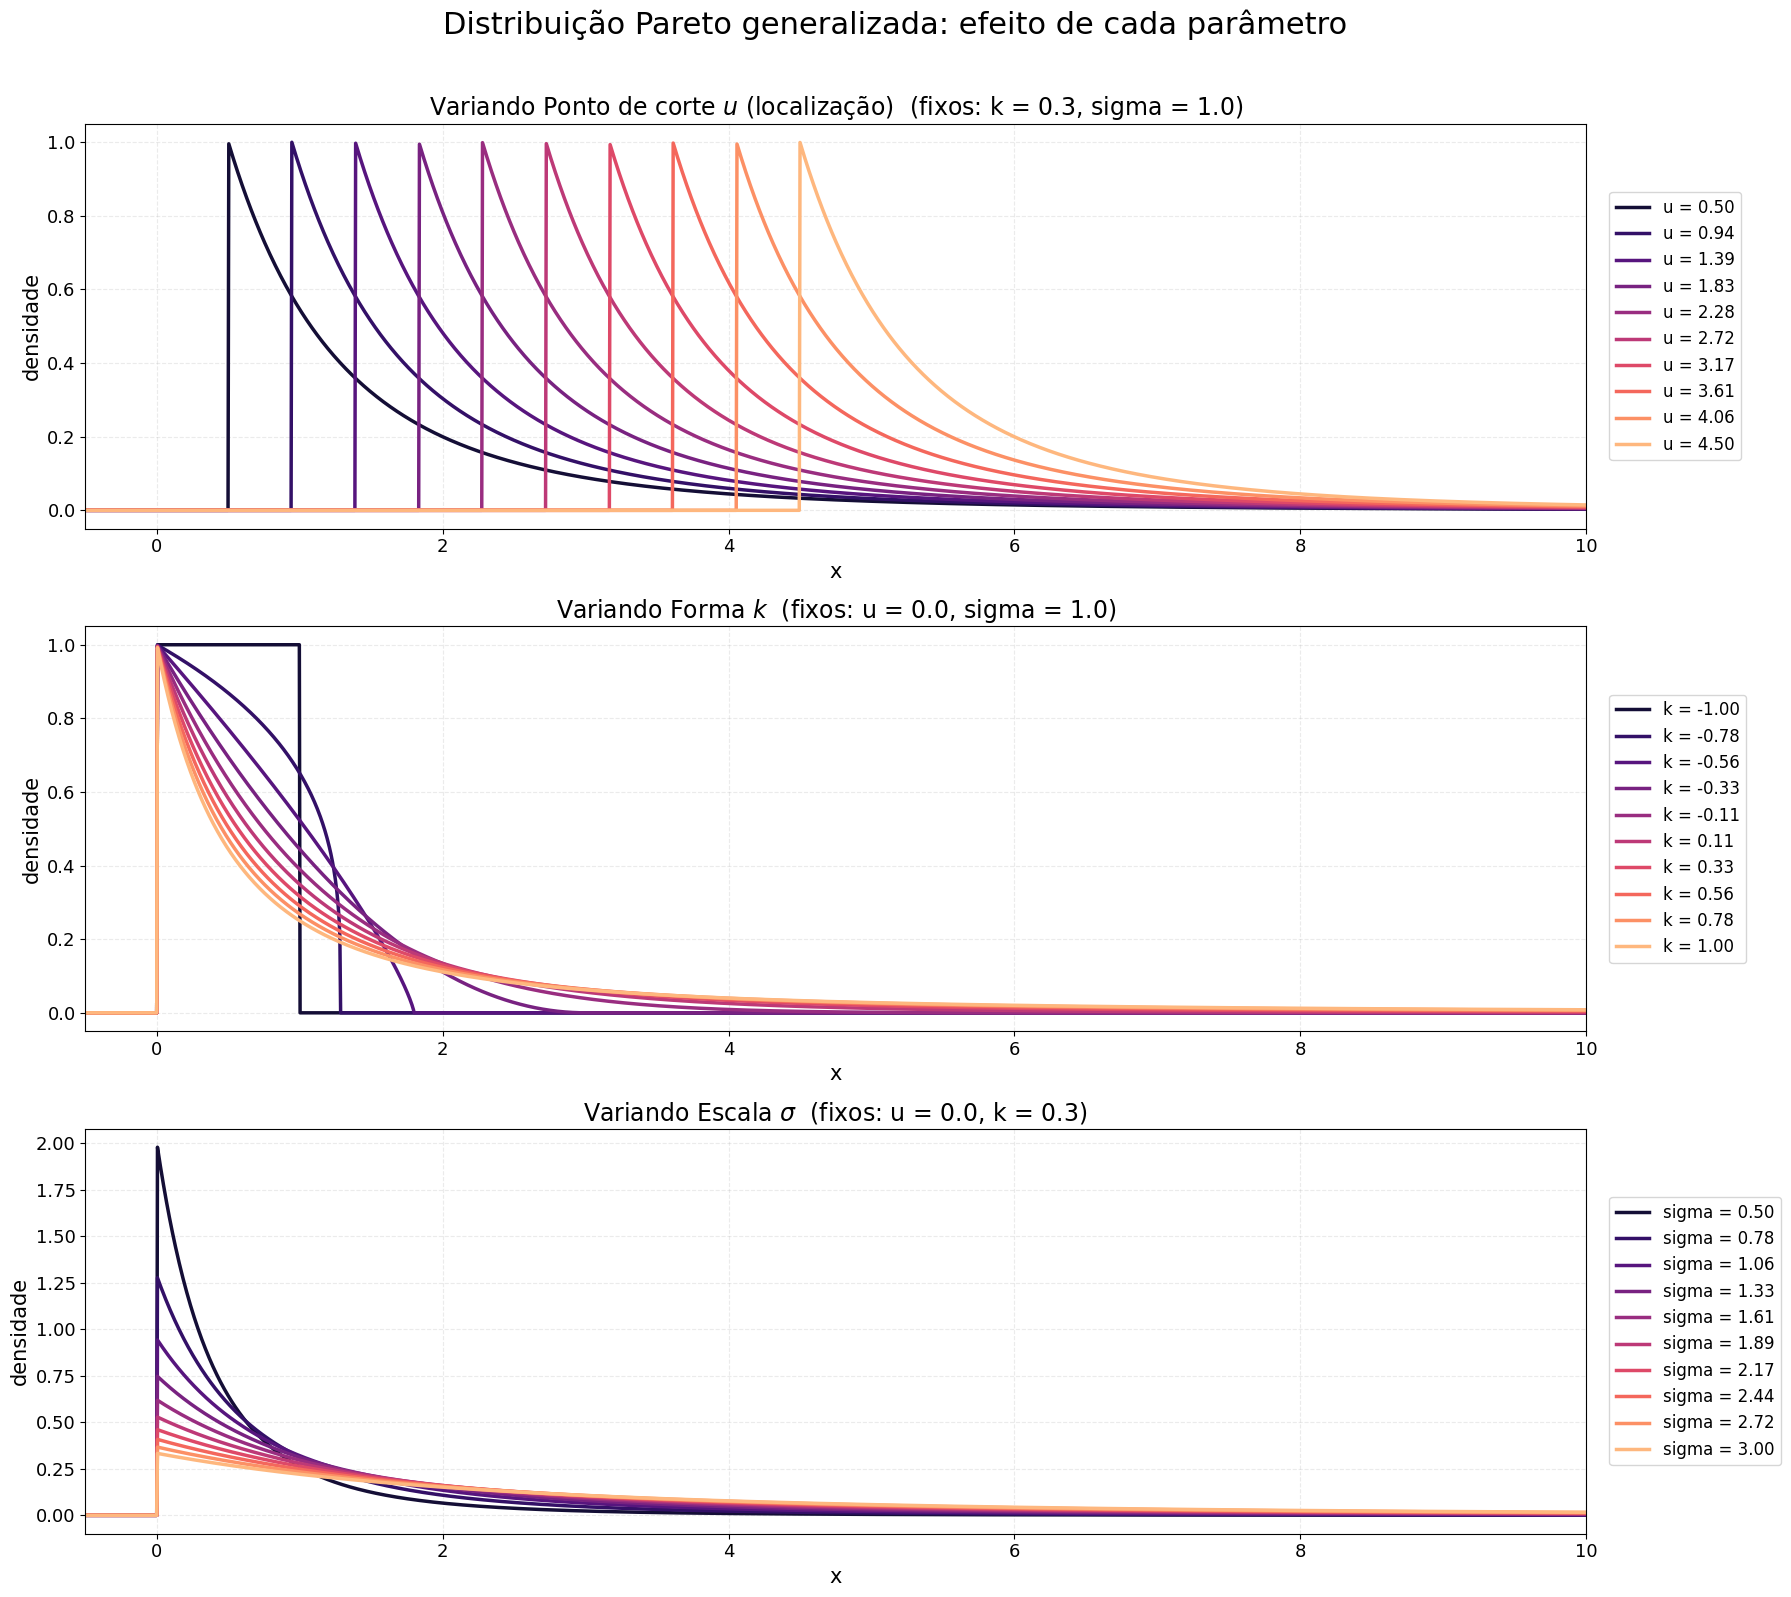

In [4]:
###################################
# Exemplo didático - Dist. Pareto #
###################################

n_curves = 10
x = np.linspace(-0.5, 10, 2000)

# Valores de referência (mantidos fixos quando outro parâmetro varia)
u_ref, k_ref, sigma_ref = 0.0, 0.3, 1.0

# Parâmetros variados em cada subplot
variations = {
    "u": {
        "values": np.linspace(0.5, 4.5, n_curves),
        "label": "Ponto de corte $u$ (localização)",
    },
    "k": {
        "values": np.linspace(-1.0, 1.0, n_curves),
        "label": "Forma $k$",
    },
    "sigma": {
        "values": np.linspace(0.5, 3.0, n_curves),
        "label": r"Escala $\sigma$",
    },
}

cmap = plt.get_cmap("magma")
colors = [
    to_hex(c) for c in cmap(np.linspace(0.10, 0.85, n_curves))
]


# -------------------------------------------------------------------------
# Resumo da configuração
# -------------------------------------------------------------------------

print("#" * 100)
print("DISTRIBUIÇÃO PARETO GENERALIZADA: f(x) = (1/sigma) [1 + k (x-u)/sigma]^(-1/k - 1)")
print("#" * 100)
print(f"Valores de referência: u = {u_ref}, k = {k_ref}, sigma = {sigma_ref}")
print("Suporte: x >= u (k >= 0)  |  u <= x <= u - sigma/k (k < 0)")
for name, v in variations.items():
    print(f"{name:<6} varia de {v['values'][0]:.2f} a {v['values'][-1]:.2f} ")
    print(f"({n_curves} curvas)")
print("#" * 100)


# -------------------------------------------------------------------------
# Visualização
# -------------------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3, ncols=1,
    figsize=(18, 16)
)

fig.suptitle(
    "Distribuição Pareto generalizada: efeito de cada parâmetro",
    fontsize=22,
    y=0.995
)

for ax, (name, var) in zip(axes, variations.items()):

    for value, color in zip(var["values"], colors):

        u, k, sigma = u_ref, k_ref, sigma_ref
        if name == "u":
            u = value
        elif name == "k":
            k = value
        else:
            sigma = value

        # scipy: c = k (forma), loc = u (corte), scale = sigma (escala)
        pdf = stats.genpareto.pdf(x, c=k, loc=u, scale=sigma)

        ax.plot(
            x, pdf,
            color=color, linewidth=2.5,
            label=f"{name} = {value:.2f}"
        )

    fixed = {"u": u_ref, "k": k_ref, "sigma": sigma_ref}
    fixed.pop(name)
    fixed_txt = ", ".join(f"{p} = {v}" for p, v in fixed.items())

    ax.set_xlabel("x", fontsize=15)
    ax.set_ylabel("densidade", fontsize=15)
    ax.set_title(
        f"Variando {var['label']}  (fixos: {fixed_txt})",
        fontsize=17
    )
    ax.set_xlim(x[0], x[-1])
    ax.tick_params(axis="both", labelsize=13)
    ax.grid(alpha=0.25, linestyle="--")
    ax.legend(fontsize=12, loc="center left", bbox_to_anchor=(1.01, 0.5))

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

####################################################################################################
CONFIGURAÇÃO DA SIMULAÇÃO: PSIS SOBRE PESOS DE IMPORTÂNCIA SINTÉTICOS
####################################################################################################
Amostras:         K = 5000  (reff = 1.0)
Cauda do PSIS:    M = 213 maiores pesos (4.3% da amostra)
Suavização:       Pareto generalizada ajustada à cauda (arviz.psislw)
----------------------------------------------------------------------------------------------------
Geração dos pesos brutos (forma funcional única):
  log w = k * E, com E ~ Exponencial(1)
  Escala maior (decaimento mais lento) -> cauda mais pesada -> k maior.
  Escala menor (decaimento mais rápido) -> cauda mais leve -> k menor.
####################################################################################################
Leitura: k-hat < 0,5 (leve); 0,5-0,7 (limiar); > 0,7 (pouco confiável).



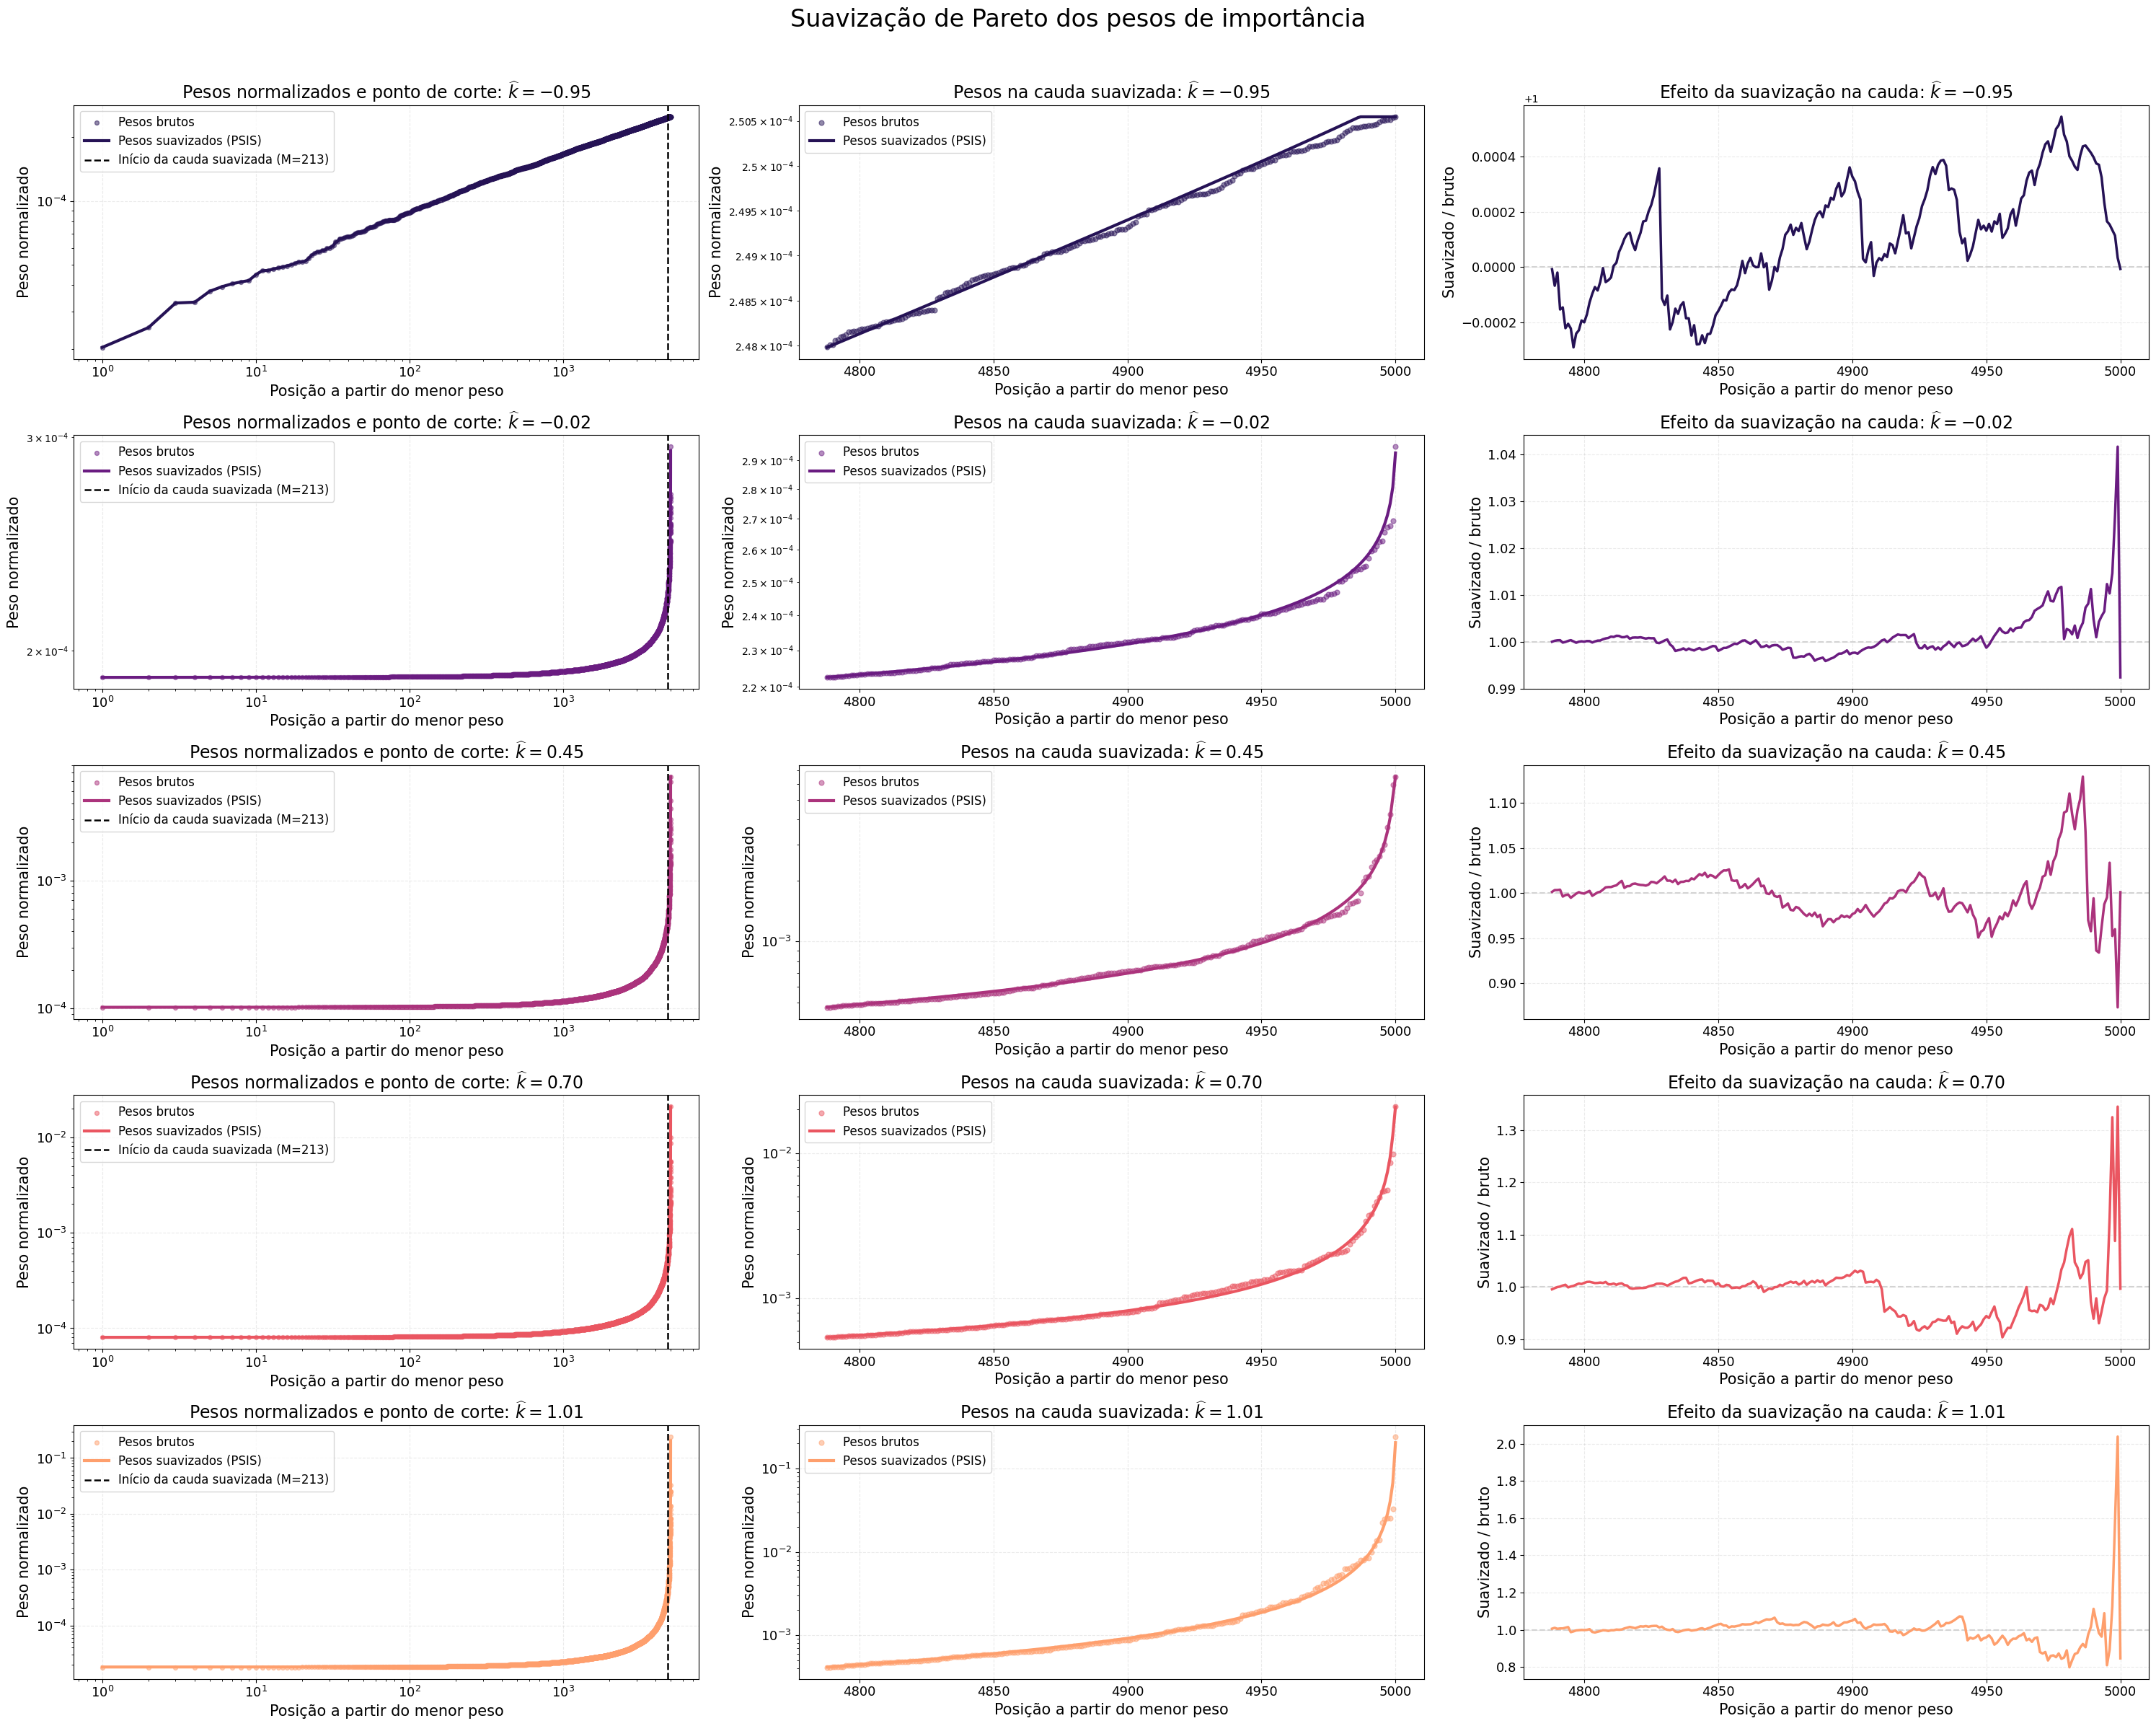

In [5]:
###########################
# Exemplo didático - PSIS #
###########################

rng = np.random.default_rng(121)

n_samples = 5000
reff = 1.0
log_y = True   # escala logarítmica no eixo y dos gráficos de pesos

# Forma funcional única: log w = k * E, com E ~ Exponential(1).
# Escalar os log-pesos por k equivale a log w ~ Exponential(taxa = 1/k), logo
#   P(w > t) = t^(-1/k)  ->  w ~ Pareto, cauda de Pareto generalizada com forma k.
#   k maior (escala maior) -> decaimento mais lento  -> cauda mais pesada
#   k menor (escala menor) -> decaimento mais rápido -> cauda mais leve
k_values = [-0.25, 0.05, 0.5, 0.6, 1.0]

scenarios = {
    f"Cenário {i}": {"k": k}
    for i, k in enumerate(k_values, start=1)
}

cmap = plt.get_cmap("magma")
colors = [
    to_hex(c) for c in cmap(np.linspace(0.15, 0.80, len(scenarios)))
]


# -------------------------------------------------------------------------
# Funções auxiliares
# -------------------------------------------------------------------------

def generate_log_weights(spec, size, rng):
    """Log-pesos: exponencial padrão escalada por spec['k']."""
    return spec["k"] * rng.exponential(scale=1.0, size=size)


def psis_tail_length(size, reff=1.0):
    """Número de pesos na cauda suavizada pelo PSIS."""
    return int(np.ceil(min(size / 5, 3 * np.sqrt(size / reff))))


# -------------------------------------------------------------------------
# Resumo da configuração do estudo
# -------------------------------------------------------------------------

tail_length = psis_tail_length(n_samples, reff)

print("#" * 100)
print("CONFIGURAÇÃO DA SIMULAÇÃO: PSIS SOBRE PESOS DE IMPORTÂNCIA SINTÉTICOS")
print("#" * 100)
print(f"Amostras:         K = {n_samples}  (reff = {reff})")
print(f"Cauda do PSIS:    M = {tail_length} maiores pesos "
      f"({100 * tail_length / n_samples:.1f}% da amostra)")
print(f"Suavização:       Pareto generalizada ajustada à cauda (arviz.psislw)")
print("-" * 100)
print("Geração dos pesos brutos (forma funcional única):")
print("  log w = k * E, com E ~ Exponencial(1)")
print("  Escala maior (decaimento mais lento) -> cauda mais pesada -> k maior.")
print("  Escala menor (decaimento mais rápido) -> cauda mais leve -> k menor.")
print("#" * 100)
print("Leitura: k-hat < 0,5 (leve); 0,5-0,7 (limiar); > 0,7 (pouco confiável).")
print()


# -------------------------------------------------------------------------
# Simulação e aplicação do PSIS
# -------------------------------------------------------------------------

results = {}

for scenario, spec in scenarios.items():

    raw_log_weights = generate_log_weights(spec, n_samples, rng)

    # PSIS: log-pesos suavizados (normalizados) e k-hat
    smoothed_log_weights, k_hat = az.psislw(raw_log_weights.copy(), reff=reff)

    # Pesos brutos normalizados e pesos suavizados
    raw_weights = np.exp(raw_log_weights - logsumexp(raw_log_weights))
    smoothed_weights = np.exp(smoothed_log_weights)

    results[scenario] = {
        "k_true": spec["k"],
        "k_hat": float(k_hat),
        "raw_sorted": np.sort(raw_weights),
        "smoothed_sorted": np.sort(smoothed_weights),
        "tail_length": tail_length,
    }


# -------------------------------------------------------------------------
# Visualização
# -------------------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=len(results), ncols=3,
    figsize=(30, 24)
)

fig.suptitle(
    "Suavização de Pareto dos pesos de importância",
    fontsize=24,
    y=0.995
)

ranks = np.arange(1, n_samples + 1)   # posição a partir do menor peso

for row, ((scenario, r), color) in enumerate(zip(results.items(), colors)):

    ax_w, ax_tail, ax_ratio = axes[row]
    M = r["tail_length"]

    # ---- Painel esquerdo: pesos ordenados do menor para o maior (log-log) -
    ax_w.scatter(
        ranks, r["raw_sorted"],
        s=18, color=color, alpha=0.5,
        label="Pesos brutos"
    )
    ax_w.plot(
        ranks, r["smoothed_sorted"],
        color=color, linewidth=3,
        label="Pesos suavizados (PSIS)"
    )
    ax_w.axvline(
        n_samples - M,
        color="black", linestyle="--", linewidth=1.8,
        label=f"Início da cauda suavizada (M={M})"
    )

    ax_w.set_xscale("log")
    if log_y:
        ax_w.set_yscale("log")

    ax_w.set_xlabel("Posição a partir do menor peso", fontsize=15)
    ax_w.set_ylabel("Peso normalizado", fontsize=15)
    ax_w.set_title(
        "Pesos normalizados e ponto de corte: "
        rf"$\widehat{{k}}={r['k_hat']:.2f}$",
        fontsize=17
    )
    ax_w.tick_params(axis="both", labelsize=13)
    ax_w.grid(alpha=0.25, linestyle="--")
    ax_w.legend(fontsize=12, loc="upper left")

    # ---- Painel central: mesmos pesos, restrito à cauda (eixo x linear) --
    tail_ranks = ranks[-M:]

    ax_tail.scatter(
        tail_ranks, r["raw_sorted"][-M:],
        s=24, color=color, alpha=0.5,
        label="Pesos brutos"
    )
    ax_tail.plot(
        tail_ranks, r["smoothed_sorted"][-M:],
        color=color, linewidth=3,
        label="Pesos suavizados (PSIS)"
    )

    if log_y:
        ax_tail.set_yscale("log")

    ax_tail.set_xlabel("Posição a partir do menor peso", fontsize=15)
    ax_tail.set_ylabel("Peso normalizado", fontsize=15)
    ax_tail.set_title(
        "Pesos na cauda suavizada: "
        rf"$\widehat{{k}}={r['k_hat']:.2f}$",
        fontsize=17
    )
    ax_tail.tick_params(axis="both", labelsize=13)
    ax_tail.grid(alpha=0.25, linestyle="--")
    ax_tail.legend(fontsize=12, loc="upper left")

    # ---- Painel direito: razão suavizado / bruto na cauda ---------------
    ax_ratio.axhline(1, color="lightgray", linestyle="--")
    ax_ratio.plot(
        tail_ranks, r["smoothed_sorted"][-M:] / r["raw_sorted"][-M:],
        color=color, linewidth=2.5
    )

    ax_ratio.set_xlabel("Posição a partir do menor peso", fontsize=15)
    ax_ratio.set_ylabel("Suavizado / bruto", fontsize=15)
    ax_ratio.set_title(
        "Efeito da suavização na cauda: "
        rf"$\widehat{{k}}={r['k_hat']:.2f}$",
        fontsize=17
    )
    ax_ratio.tick_params(axis="both", labelsize=13)
    ax_ratio.grid(alpha=0.25, linestyle="--")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


### Sensibilidade local (Pérez, Martín & Rufo, 2006)

As derivadas parciais de uma quantidade a posteriori em relação ao parâmetro perturbado podem ser estimadas por Monte Carlo usando as próprias amostras da posteriori base, sem nova amostragem.

#### Identidade geral e estimador MCMC

Seja $\mathcal H(\xi)=\mathbb E_{\xi}[h(\mathbf B)]$, em que $\xi$ representa os parâmetros da priori e do modelo das fontes, e $\xi_j$ é o componente perturbado. Considerando $h$ fixa, sem dependência explícita de $\xi$, tem-se:

$$
\left[
\frac{\partial \mathcal H}{\partial \xi_j}
\right]_{\xi=\xi^{0}}
=
\mathbb E_{0}
\left[
\big(h(\mathbf B)-\mathcal H^{0}\big)
\eta_{\xi_j}(\mathbf B)
\right]
=
\operatorname{Cov}_{0}
\big(h,\eta_{\xi_j}\big).
$$

O índice $0$ indica que as esperanças e covariâncias são calculadas sob a posteriori base.

O escore da posteriori é a derivada parcial de sua log-densidade em relação ao parâmetro perturbado:

$$
\eta_{\xi_j}(\mathbf B)
=
\left[
\frac{\partial
\log p_{\mathbf B\mid\mathcal X}
(\mathbf B\mid\mathcal X;\xi)}
{\partial \xi_j}
\right]_{\xi=\xi^{0}}.
$$

Para perturbações da priori ou da verossimilhança, podem-se usar os escores abaixo. Eles diferem do escore da posteriori normalizada apenas por uma constante em $\mathbf B$, que não altera a covariância.

| Perturbação | Escore equivalente na covariância |
|---|---|
| Priori | $\eta_{\xi_p}(\mathbf B)=\left[\frac{\partial \log p_{\mathbf b}(\mathbf b;\xi_p)}{\partial \xi_p}\right]_{\xi_p=\xi_p^{0}}$, com $\mathbf b=\mathrm{vec}(\mathbf B)$ |
| Modelo das fontes | $\eta_{\xi_s}(\mathbf B)=\left[\frac{\partial \log \mathcal L_{\mathcal X}(\mathbf B;\xi_s)}{\partial \xi_s}\right]_{\xi_s=\xi_s^{0}}$ |

Com $\hat{\mathcal H}^{0}=K^{-1}\sum_{k=1}^{K}h(\mathbf B_k)$, o estimador MCMC correspondente é:

$$
\widehat{
\left[
\frac{\partial \mathcal H}{\partial \xi_j}
\right]_{\xi=\xi^{0}}
}
=
\frac{1}{K}
\sum_{k=1}^{K}
\big(h(\mathbf B_k)-\hat{\mathcal H}^{0}\big)
\eta_{\xi_j}(\mathbf B_k).
$$

#### Aplicação à média posterior

Neste ensaio, a análise local considera a média posterior de cada elemento $b_{ij}$ da matriz de separação:

$$
\bar b_{ij}(\xi)=\mathbb E_{\xi}[b_{ij}].
$$

Como $h(\mathbf B)=b_{ij}$ não depende explicitamente de $\xi$, sua sensibilidade é:

$$
\left[
\frac{\partial \bar b_{ij}}{\partial \xi_j}
\right]_{\xi=\xi^{0}}
=
\operatorname{Cov}_{0}(b_{ij},\eta_{\xi_j}).
$$

Para evitar confusão entre o índice da matriz e o índice do parâmetro perturbado, podemos escrever este último como $a$:

$$
\left[
\frac{\partial \bar b_{ij}}{\partial \xi_a}
\right]_{\xi=\xi^{0}}
=
\operatorname{Cov}_{0}(b_{ij},\eta_{\xi_a}).
$$

Com $\hat{\bar b}_{ij}^{0}=K^{-1}\sum_{k=1}^{K}[\mathbf B_k]_{ij}$, a estimativa é:

$$
\widehat{
\left[
\frac{\partial \bar b_{ij}}{\partial \xi_a}
\right]_{\xi=\xi^{0}}
}
=
\frac{1}{K}
\sum_{k=1}^{K}
\big([\mathbf B_k]_{ij}-\hat{\bar b}_{ij}^{0}\big)
\eta_{\xi_a}(\mathbf B_k).
$$

Essa derivada quantifica a mudança local da média posterior em resposta à variação de um parâmetro da priori ou do modelo das fontes, avaliada no ponto base.

### Escores usados

Os escores são derivados diretamente em relação aos parâmetros $\alpha$, $\sigma_p$, $\nu_p$, $\mu_s$, $\sigma_s$ e $\nu_s$, e não em relação aos seus logaritmos. Para $\sigma_p$, $\mu_s$ e $\sigma_s$, calculam-se derivadas parciais, mantendo os demais parâmetros fixos. Para $\alpha$, deriva-se ao longo da trajetória do centro da priori, mantendo sua escala e seus graus de liberdade fixos.

Nas análises de peso de cauda, a escala acompanha os graus de liberdade segundo

$$
\sigma(\nu)=\sqrt{\frac{\nu-2}{\nu}},
\qquad
\nu>2,
\qquad
\frac{d\sigma}{d\nu}=\frac{1}{\nu^2\sigma}.
$$

Nesses casos, o escore é a **derivada total em relação a $\nu$**, incluindo a contribuição da mudança de escala.

As varreduras de escala e de cauda das fontes permanecem **relativas**, com $p=\sigma_s^*/\sigma_s^0$ e $r=\nu_s^*/\nu_s^0$. Entretanto, os escores são calculados diretamente em relação a $\sigma_s$ e $\nu_s$, respectivamente, e não em relação aos multiplicadores $p$ e $r$. Todos os escores são avaliados nos valores base $\xi_p^0$ e $\xi_s^0$.

Considera-se uma Student-t de localização $\mu_s$ e escala $\sigma_s$ para as fontes, e uma t multivariada de localização $\boldsymbol\theta_p$ e matriz de forma $\sigma_p^2\mathbf I_d$ para a priori.

**Notação:**

$$
\mathbf b=\operatorname{vec}(\mathbf B),
\qquad
\underline{\mathbf b}=\operatorname{vec}(\mathbf B_\star),
\qquad
\mathbf B_\star=\mathbf A^{-1},
\qquad
\mathbf i=\operatorname{vec}(\mathbf I_L),
\qquad
d=L^2=4.
$$

$$
z_{\ell n}
=
\frac{[\mathbf B\mathbf x(n)]_\ell-\mu_s}{\sigma_s},
\qquad
\delta^2
=
\frac{(\mathbf b-\boldsymbol\theta_p)^\top(\mathbf b-\boldsymbol\theta_p)}
{\sigma_p^2},
\qquad
\boldsymbol\theta_p(\alpha)
=
(1-\alpha)\,\underline{\mathbf b}+\alpha\,\mathbf i.
$$

Aqui, $L$ é o número de fontes e $N$ é o número de observações. Nas expressões de uma única contribuição das fontes, escreve-se $z=z_{\ell n}$.

Definem-se as log-densidades

$$
\ell_s(y;\mu_s,\sigma_s,\nu_s)
=
\log f_s(y;\mu_s,\sigma_s,\nu_s),
\qquad
\ell_p(\mathbf b;\boldsymbol\theta_p,\sigma_p,\nu_p)
=
\log p_{\mathbf b}(\mathbf b;\boldsymbol\theta_p,\sigma_p,\nu_p).
$$

**Termos auxiliares completos:**

As derivadas parciais em relação às escalas, mantendo os demais parâmetros fixos, são

$$
k_s(z)
:=
\frac{\partial\ell_s}{\partial\sigma_s}
=
-\frac{1}{\sigma_s}
+
\frac{(\nu_s+1)z^2}{\sigma_s(\nu_s+z^2)},
$$

$$
k_p(\delta^2)
:=
\frac{\partial\ell_p}{\partial\sigma_p}
=
-\frac{d}{\sigma_p}
+
\frac{(\nu_p+d)\delta^2}{\sigma_p(\nu_p+\delta^2)}.
$$

As derivadas parciais em relação aos graus de liberdade, mantendo a escala e a localização fixas, são

$$
h_s(z)
:=
\left.\frac{\partial\ell_s}{\partial\nu_s}\right|_{\mu_s,\sigma_s\ \mathrm{fixos}}
=
\frac12
\left[
\psi\!\left(\frac{\nu_s+1}{2}\right)
-
\psi\!\left(\frac{\nu_s}{2}\right)
-
\frac{1}{\nu_s}
\right]
-
\frac12\log\!\left(1+\frac{z^2}{\nu_s}\right)
+
\frac{(\nu_s+1)z^2}{2\nu_s(\nu_s+z^2)},
$$

$$
h_p(\delta^2)
:=
\left.\frac{\partial\ell_p}{\partial\nu_p}\right|_{\boldsymbol\theta_p,\sigma_p\ \mathrm{fixos}}
=
\frac12
\left[
\psi\!\left(\frac{\nu_p+d}{2}\right)
-
\psi\!\left(\frac{\nu_p}{2}\right)
-
\frac{d}{\nu_p}
\right]
-
\frac12\log\!\left(1+\frac{\delta^2}{\nu_p}\right)
+
\frac{(\nu_p+d)\delta^2}{2\nu_p(\nu_p+\delta^2)}.
$$

Os argumentos abreviados $z$ e $\delta^2$ não eliminam a dependência desses auxiliares nos parâmetros das respectivas distribuições.

**Escores completos:**

Na tabela, os escores das fontes correspondem a **uma observação e uma fonte**. O escore da verossimilhança completa é obtido somando essas contribuições em $n=1,\ldots,N$ e $\ell=1,\ldots,L$. Os escores da priori já correspondem à densidade multivariada completa.

| Parâmetro da derivada | Escore completo |
|---|---|
| $\mu_s$, com $\sigma_s$ e $\nu_s$ fixos | $\dfrac{(\nu_s+1)z}{\sigma_s(\nu_s+z^2)}$ |
| $\sigma_s$, com $\mu_s$ e $\nu_s$ fixos | $k_s(z)=-\dfrac{1}{\sigma_s}+\dfrac{(\nu_s+1)z^2}{\sigma_s(\nu_s+z^2)}$ |
| $\nu_s$, com $\sigma_s=\sigma_s(\nu_s)$ e $\mu_s$ fixo | $h_s(z)+\dfrac{k_s(z)}{\nu_s^2\sigma_s}=h_s(z)-\dfrac{1}{\nu_s^2\sigma_s^2}+\dfrac{(\nu_s+1)z^2}{\nu_s^2\sigma_s^2(\nu_s+z^2)}$ |
| $\alpha$, com $\dfrac{\partial\boldsymbol\theta_p}{\partial\alpha}=\mathbf i-\underline{\mathbf b}$ | $\dfrac{(\nu_p+d)(\mathbf b-\boldsymbol\theta_p)^\top(\mathbf i-\underline{\mathbf b})}{\sigma_p^2(\nu_p+\delta^2)}$ |
| $\sigma_p$, com $\boldsymbol\theta_p$ e $\nu_p$ fixos | $k_p(\delta^2)=-\dfrac{d}{\sigma_p}+\dfrac{(\nu_p+d)\delta^2}{\sigma_p(\nu_p+\delta^2)}$ |
| $\nu_p$, com $\sigma_p=\sigma_p(\nu_p)$ e $\boldsymbol\theta_p$ fixo | $h_p(\delta^2)+\dfrac{k_p(\delta^2)}{\nu_p^2\sigma_p}=h_p(\delta^2)-\dfrac{d}{\nu_p^2\sigma_p^2}+\dfrac{(\nu_p+d)\delta^2}{\nu_p^2\sigma_p^2(\nu_p+\delta^2)}$ |

\* **Implementação:** a tabela apresenta os escores completos, inclusive os termos constantes em $\mathbf B$. A implementação proposta considera apenas os termos dependentes de $\mathbf B$, pois constantes aditivas não alteram a covariância usada no cálculo da sensibilidade. Explicitamente, se $\eta_a(\mathbf B)$ é o escore completo e $C_a$ reúne os termos independentes de $\mathbf B$, a expressão implementada é $\widetilde\eta_a(\mathbf B)=\eta_a(\mathbf B)-C_a$, de modo que $\operatorname{Cov}_0(h,\widetilde\eta_a)=\operatorname{Cov}_0(h,\eta_a)$.

A função $\psi$, denominada digama, é definida por

$$
\psi(t)=\frac{\Gamma'(t)}{\Gamma(t)},
$$

onde $\Gamma$ é a função gama.

> **Nota sobre os eixos das varreduras:** a parametrização da grade não modifica a variável da derivada. A grade logarítmica da escala da priori contém valores de $\sigma_p$, e seu escore permanece em $\partial/\partial\sigma_p$. Da mesma forma, as grades relativas das fontes contêm valores de $p$ e $r$, mas as sensibilidades são calculadas em relação a $\sigma_s$ e $\nu_s$.
>
> Para comparar essas sensibilidades com as inclinações das curvas de IS nos eixos relativos, definem-se $D_{\sigma_s}:=\left.d\mathcal H/d\sigma_s\right|_{\sigma_s^0}$ e $D_{\nu_s}:=\left.d\mathcal H/d\nu_s\right|_{\nu_s^0}$, sendo a segunda uma derivada total ao longo da trajetória de variância unitária. As aproximações de primeira ordem são
>
> $$
> \mathcal H(\sigma_s^0p)
> \approx
> \mathcal H(\sigma_s^0)
> +
> \sigma_s^0D_{\sigma_s}(p-1),
> $$
>
> $$
> \mathcal H(\nu_s^0r)
> \approx
> \mathcal H(\nu_s^0)
> +
> \nu_s^0D_{\nu_s}(r-1).
> $$
>
> Na segunda expressão, $\mathcal H(\nu_s)$ já incorpora o ajuste de escala $\sigma_s(\nu_s)$. Os fatores $\sigma_s^0$ e $\nu_s^0$ convertem as inclinações para os eixos relativos; eles não fazem parte dos escores diretos apresentados na tabela.

## Saídas esperadas (por fonte × perturbação × realização)

- Curvas dos 4 momentos de $b_{ij}$ em função do parâmetro perturbado, considerando tanto hiperparâmetros da priori ($\boldsymbol\theta_p^{*}$, $\sigma_p^{*}$ e $\nu_p^{*}$) quanto do modelo das fontes ($\mu_s^{*}$, $\sigma_s^{*}$ e $\nu_s^{*}$).
- Derivadas locais da média de $b_{ij}$, no ponto base.
- Curva de $\hat k$ → região de validade.
- Agregação nas realizações que convergiram, comparando rs1 → rs10.

## Posicionamento metodológico

| Abordagem | Tipo | Uso no ensaio |
|---|---|---|
| Pérez et al. (2006) | Local, paramétrica, mesma amostra MCMC | **Sim** — derivadas |
| PSIS (Vehtari et al., 2024) | Reponderação estabilizada + diagnóstico | **Sim** — varreduras globais e $\hat k$ |
| *Power-scaling* (Kallioinen et al.) | Local, perturbação por potências da priori/verossimilhança | **Fluxo** (priori e verossimilhança separadas) |
